# San Diego ERA5 Initial Analysis

add `~/.cdsapirc` file with API key

   !pip install "cdsapi>=0.7.2" netcdf4

In [ ]:
   !pip install "cdsapi>=0.7.2" netcdf4

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.6/10.6 MB 27.3 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.7/1.7 MB 46.0 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5/5 [cdsapi]


In [ ]:
# where api key was

85

In [ ]:
from importlib.metadata import version
print(version("cdsapi"))

0.7.7


In [ ]:
import glob, os, zipfile
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

DATA_DIR = "era5_sandiego"
AREA = [33.5, -117.6, 32.5, -116.1]
os.makedirs(DATA_DIR, exist_ok=True)

In [ ]:
# getting data for the 2024 year
RUN_DOWNLOAD = True

VARIABLES = [
    "10m_u_component_of_wind",
    "10m_v_component_of_wind",
    "total_precipitation",
]

import cdsapi
client = cdsapi.Client()

for month in range(1, 13):
    tag = f"2024_{month:02d}"
    if glob.glob(f"{DATA_DIR}/era5_{tag}*"):
        continue
    client.retrieve(
        "reanalysis-era5-single-levels",
        {
            "product_type": ["reanalysis"],
            "variable": VARIABLES,
            "year": ["2024"],
            "month": [f"{month:02d}"],
            "day": [f"{d:02d}" for d in range(1, 32)],
            "time": [f"{h:02d}:00" for h in range(24)],
            "area": AREA,
            "data_format": "netcdf",
            "download_format": "unarchived",
        },
        f"{DATA_DIR}/era5_{tag}.nc",
    )

2026-11-02 03:02:44,630 INFO [2026-10-06T00:00:00Z] **Data Stores Service protection measures** affecting data downloads and account access: [please read our Announcement](https://forum.ecmwf.int/t/data-stores-service-protection-measures-affecting-data-downloads-and-account-access-cds-ads-ewds-ecds/15481) before enquiring with ECMWF Support.
INFO:ecmwf.datastores.legacy_client:[2026-10-06T00:00:00Z] **Data Stores Service protection measures** affecting data downloads and account access: [please read our Announcement](https://forum.ecmwf.int/t/data-stores-service-protection-measures-affecting-data-downloads-and-account-access-cds-ads-ewds-ecds/15481) before enquiring with ECMWF Support.
2026-11-02 03:02:45,162 INFO Request ID is 6832f268-cfea-4757-89a8-63d06d668b64
INFO:ecmwf.datastores.legacy_client:Request ID is 6832f268-cfea-4757-89a8-63d06d668b64
2026-11-02 03:02:45,307 INFO status has been updated to accepted
INFO:ecmwf.datastores.legacy_client:status has been updated to accepted
2

5de5b2069feef89bcee3e3ce01a37945.zip:   0%|          | 0.00/284k [00:00<?, ?B/s]

2026-11-02 03:05:41,055 INFO Request ID is 5ccb3220-8ebb-4088-99ca-c0bdf9ccd65d
INFO:ecmwf.datastores.legacy_client:Request ID is 5ccb3220-8ebb-4088-99ca-c0bdf9ccd65d
2026-11-02 03:05:41,195 INFO status has been updated to accepted
INFO:ecmwf.datastores.legacy_client:status has been updated to accepted
2026-11-02 03:06:03,313 INFO status has been updated to running
INFO:ecmwf.datastores.legacy_client:status has been updated to running
2026-11-02 03:08:34,601 INFO status has been updated to successful
INFO:ecmwf.datastores.legacy_client:status has been updated to successful


a1e672aad692ee9cc895e08dd0654f66.zip:   0%|          | 0.00/282k [00:00<?, ?B/s]

2026-11-02 03:08:36,948 INFO Request ID is 99fd4ce0-b3e8-4791-bffc-3ca83c11cfa6
INFO:ecmwf.datastores.legacy_client:Request ID is 99fd4ce0-b3e8-4791-bffc-3ca83c11cfa6
2026-11-02 03:08:37,098 INFO status has been updated to accepted
INFO:ecmwf.datastores.legacy_client:status has been updated to accepted
2026-11-02 03:08:58,757 INFO status has been updated to running
INFO:ecmwf.datastores.legacy_client:status has been updated to running
2026-11-02 03:11:30,271 INFO status has been updated to successful
INFO:ecmwf.datastores.legacy_client:status has been updated to successful


18b9e2526e10330c14f3ca9c1608cb29.zip:   0%|          | 0.00/292k [00:00<?, ?B/s]

... (14 outputs left out)

2026-11-02 03:35:01,550 INFO Request ID is cb3fb6f2-2b85-48f8-a10b-3a47f810e776
INFO:ecmwf.datastores.legacy_client:Request ID is cb3fb6f2-2b85-48f8-a10b-3a47f810e776
2026-11-02 03:35:01,689 INFO status has been updated to accepted
INFO:ecmwf.datastores.legacy_client:status has been updated to accepted
2026-11-02 03:35:15,570 INFO status has been updated to running
INFO:ecmwf.datastores.legacy_client:status has been updated to running
2026-11-02 03:37:54,566 INFO status has been updated to successful
INFO:ecmwf.datastores.legacy_client:status has been updated to successful


cf2b8db98d680292868fc6d83934be00.zip:   0%|          | 0.00/275k [00:00<?, ?B/s]

2026-11-02 03:37:56,810 INFO Request ID is 6335d418-fb04-44c9-ba48-50066a1fa47c
INFO:ecmwf.datastores.legacy_client:Request ID is 6335d418-fb04-44c9-ba48-50066a1fa47c
2026-11-02 03:37:56,968 INFO status has been updated to accepted
INFO:ecmwf.datastores.legacy_client:status has been updated to accepted
2026-11-02 03:38:10,904 INFO status has been updated to running
INFO:ecmwf.datastores.legacy_client:status has been updated to running
2026-11-02 03:40:49,957 INFO status has been updated to successful
INFO:ecmwf.datastores.legacy_client:status has been updated to successful


be1a0b23b430538d160460b7e6f8732f.zip:   0%|          | 0.00/277k [00:00<?, ?B/s]

In [ ]:
import re

# unzipping
for f in glob.glob(f"{DATA_DIR}/*.nc"):
    if zipfile.is_zipfile(f):
        folder = f.replace(".nc", "_unz")
        with zipfile.ZipFile(f) as z:
            z.extractall(folder)
        os.rename(f, f + ".zip")

# grouping files by month
groups = {}
for f in sorted(glob.glob(f"{DATA_DIR}/**/*.nc", recursive=True)):
    m = re.search(r"era5_(\d{4})_(\d{2})", f)
    if m:
        groups.setdefault(m.group(0), []).append(f)

print(f"Found {len(groups)} months:", sorted(groups))

monthly = []
for key, files in sorted(groups.items()):
    parts = [xr.open_dataset(f) for f in files]
    monthly.append(xr.merge(parts, compat="override", join="override"))

# setting up data set n checking
time_dim = "valid_time" if "valid_time" in monthly[0].dims else "time"
ds = xr.concat(monthly, dim=time_dim)
if time_dim == "valid_time":
    ds = ds.rename({"valid_time": "time"})
ds = ds.drop_vars([v for v in ["number", "expver"] if v in ds.coords])
ds = ds.sortby("time").sel(time=slice("2024-01-01", "2024-12-31 23:00"))
ds

Found 12 months: ['era5_2024_01', 'era5_2024_02', 'era5_2024_03', 'era5_2024_04', 'era5_2024_05', 'era5_2024_06', 'era5_2024_07', 'era5_2024_08', 'era5_2024_09', 'era5_2024_10', 'era5_2024_11', 'era5_2024_12']


<xarray.Dataset> Size: 3MB
Dimensions:    (time: 8784, latitude: 5, longitude: 6)
Coordinates:
  * time       (time) datetime64[ns] 70kB 2024-01-01 ... 2024-12-31T23:00:00
  * latitude   (latitude) float64 40B 33.5 33.25 33.0 32.75 32.5
  * longitude  (longitude) float64 48B -117.5 -117.2 -117.0 -116.8 -116.5 -116.2
Data variables:
    tp         (time, latitude, longitude) float32 1MB 0.0 0.0 0.0 ... 0.0 0.0
    u10        (time, latitude, longitude) float32 1MB -0.8332 -0.4338 ... -1.0
    v10        (time, latitude, longitude) float32 1MB -0.7923 ... -0.02173
Attributes:
    GRIB_centre:             ecmf
    GRIB_centreDescription:  European Centre for Medium-Range Weather Forecasts
    GRIB_subCentre:          0
    Conventions:             CF-1.7
    institution:             European Centre for Medium-Range Weather Forecasts
    history:                 2026-11-02T03:05 GRIB to CDM+CF via cfgrib-0.9.1...

In [ ]:
# seetting up precip spikes
POINT_MODE = "max"   # "max" or "mean"

tp_in = ds["tp"] * 39.3701
if POINT_MODE == "max":
    p1 = tp_in.max(["latitude", "longitude"]).to_series()
    p3 = tp_in.rolling(time=3).sum().max(["latitude", "longitude"]).to_series()
else:
    p1 = tp_in.mean(["latitude", "longitude"]).to_series()
    p3 = tp_in.mean(["latitude", "longitude"]).rolling(time=3).sum().to_series()

ev1 = p1[(p1 >= 1.2) & (p1 <= 1.5)]
ev1_hi = p1[p1 > 1.5]
ev3 = p3[(p3 >= 1.6) & (p3 <= 2.4)]
ev3_hi = p3[p3 > 2.4]

print(f"1-hr events 1.2-1.5 in: {len(ev1)}   (above 1.5 in: {len(ev1_hi)})")
print(f"3-hr events 1.6-2.4 in: {len(ev3)}   (above 2.4 in: {len(ev3_hi)})")
print(f"Max 1-hr: {p1.max():.2f} in on {p1.idxmax()}")
print(f"Max 3-hr: {p3.max():.2f} in on {p3.idxmax()}")

1-hr events 1.2-1.5 in: 0   (above 1.5 in: 0)
3-hr events 1.6-2.4 in: 0   (above 2.4 in: 0)
Max 1-hr: 0.27 in on 2024-02-01 19:00:00
Max 3-hr: 0.79 in on 2024-02-01 18:00:00


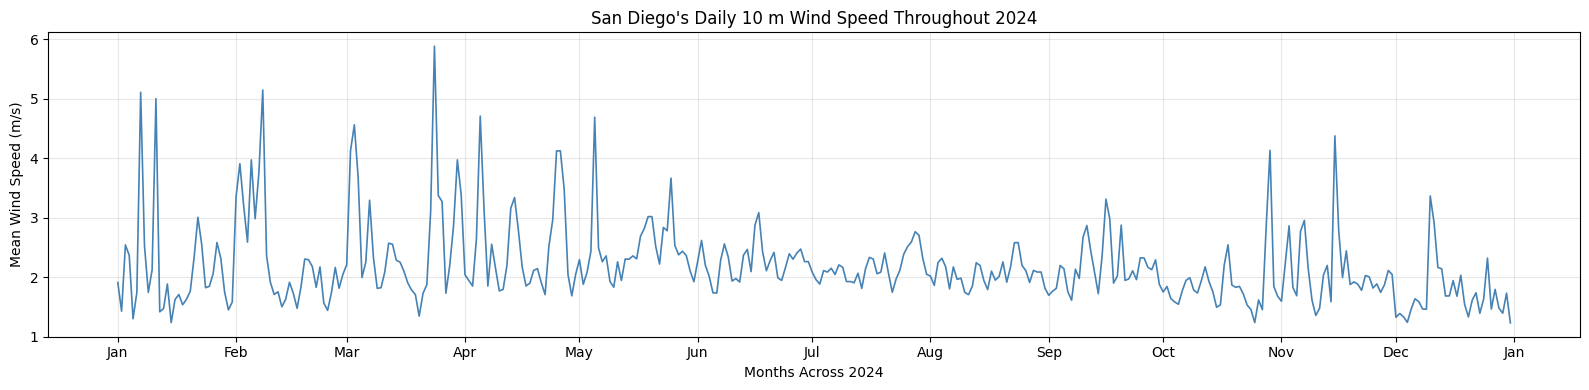

In [ ]:
# plotting for wind speed through 2024

u = ds["u10"].mean(["latitude", "longitude"])
v = ds["v10"].mean(["latitude", "longitude"])

u_d = u.resample(time="D").mean().to_series()
v_d = v.resample(time="D").mean().to_series()
spd_d = np.hypot(ds["u10"], ds["v10"]).mean(["latitude", "longitude"]).resample(time="D").mean().to_series()

fig1, ax1 = plt.subplots(figsize=(16, 4))
ax1.plot(spd_d.index, spd_d.values, color="steelblue", lw=1.2)
ax1.set_ylabel("Mean Wind Speed (m/s)")
ax1.set_xlabel("Months Across 2024")
ax1.set_title("San Diego's Daily 10 m Wind Speed Throughout 2024")
ax1.xaxis.set_major_locator(mdates.MonthLocator())
ax1.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
ax1.grid(alpha=0.3)
plt.tight_layout()
plt.show()



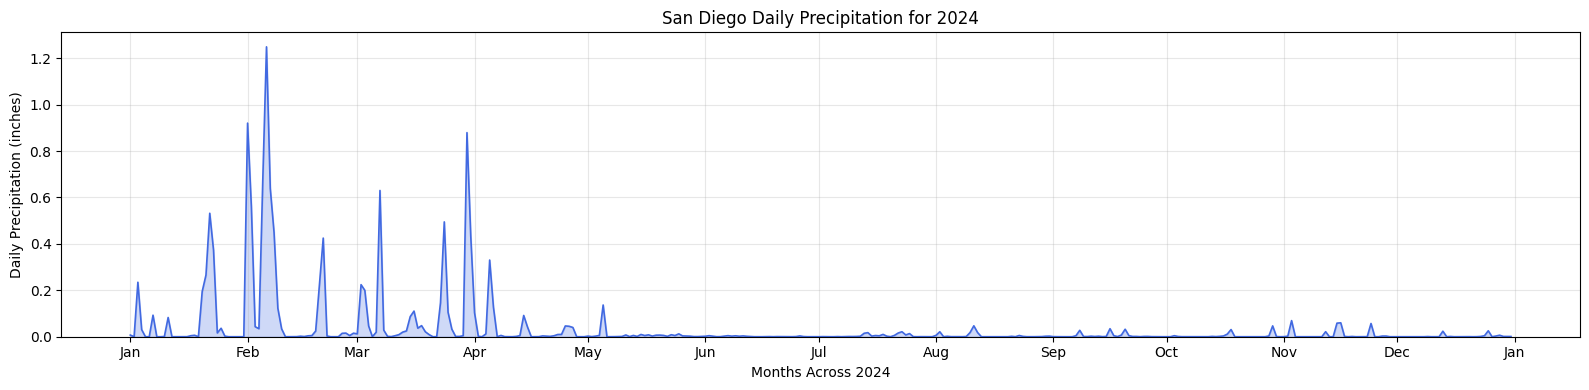

Total for 2024: 12.99 in
Wettest day: 2024-02-06 (1.25 in)


In [ ]:
# daily precip through 2024

precip_d = (ds["tp"] * 39.3701).mean(["latitude", "longitude"]).resample(time="D").sum().to_series()

fig3, ax3 = plt.subplots(figsize=(16, 4))
ax3.plot(precip_d.index, precip_d.values, color="royalblue", lw=1.2)
ax3.fill_between(precip_d.index, precip_d.values, color="royalblue", alpha=0.25)
ax3.set_ylabel("Daily Precipitation (inches)")
ax3.set_xlabel("Months Across 2024")
ax3.set_title("San Diego Daily Precipitation for 2024")
ax3.xaxis.set_major_locator(mdates.MonthLocator())
ax3.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
ax3.set_ylim(bottom=0)
ax3.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print(f"Total for 2024: {precip_d.sum():.2f} in")
print(f"Wettest day: {precip_d.idxmax().date()} ({precip_d.max():.2f} in)")

Peak hourly: 0.22 in
Peak 3-hr: 0.56 in


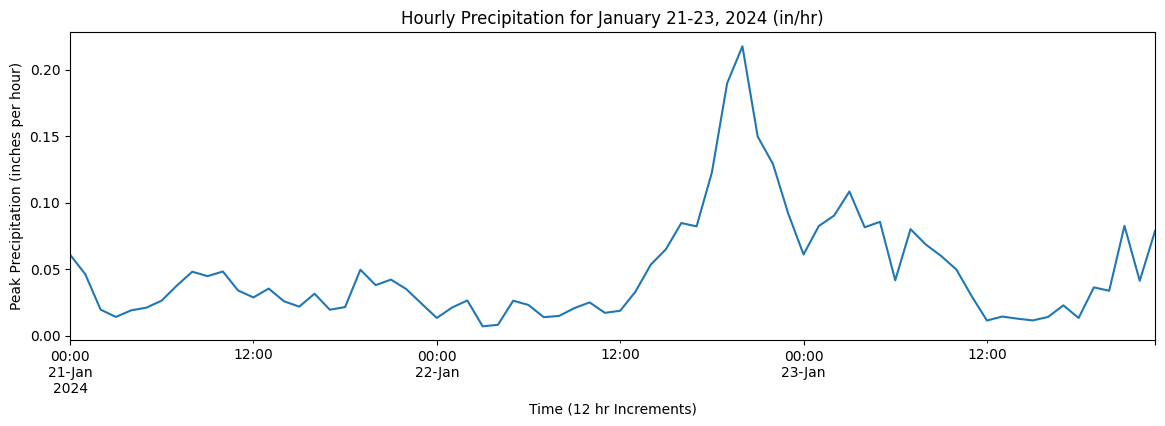

In [ ]:
# zooming into jan 2024 floods

storm = (ds["tp"] * 39.3701).max(["latitude", "longitude"]).sel(time=slice("2024-01-21", "2024-01-23"))

ax = storm.to_series().plot(figsize=(14, 4), title="Hourly Precipitation for January 21-23, 2024 (in/hr)")
ax.set_ylabel("Peak Precipitation (inches per hour)")
ax.set_xlabel("Time (12 hr Increments)")

print(f"Peak hourly: {storm.max().item():.2f} in")
print(f"Peak 3-hr: {storm.rolling(time=3).sum().max().item():.2f} in")